# HW24: verified instructor solution

Run all cells from this checkout. The only course dependency is `code/ne630_depletion.py`; NumPy, SciPy, pandas, and Matplotlib are required. This notebook embeds the numerical source from `build_hw24_solution.py`. Its outputs regenerate the private CSV evidence and figures used by `hw24_review.pdf`.

The Gd case adds exactly $10^{18}$ Gd-157 atoms/cm³ fuel; the other case has no added Gd. The fit uses 301 points over 1–40 MWd/kg. The reference time grid resolves startup more finely than the starter.

The assignment specifies numerical inputs in comments beside the starter code. Its prose supplies the equal-batch, additive-leakage, and Gd-loading assumptions.

For revised part (2), the Gd-157 and Xe-135 plots show spectrum-averaged macroscopic absorption, $\overline{\Sigma}_a=N\sum_g w_g\sigma_{a,g}$, in cm⁻¹ during the first 30 days for the Gd-bearing case. The PDF follows the revised four-part assignment, with poison absorption in (2) and the cross-section mistake in (4).

There are three calculations: shielded fuel with and without Gd, and the unshielded non-Gd case required by part (4). Cycle-error and revenue arithmetic compare the two non-Gd calculations. Part (4) replaces the dataset supplied through `xs3` with `xs_unshielded`.

The full written solutions and derivations are in [hw24_review.pdf](hw24_review.pdf). All dollar amounts below are formal arithmetic: the infinite-dilution curves violate the cycle model assumptions. All predicted limiting EOCs exceed the history, so their nonlinear residuals are deliberately unsupported.

In [1]:
%matplotlib inline

## Setup

In [2]:
from pathlib import Path
import hashlib
import gzip
import json
import platform
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy

# Locate this checkout whether executed as a script or in a notebook.
START = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
ROOT = next(p for p in (START, *START.parents) if (p / "code/ne630_depletion.py").is_file())
OUT = ROOT / "homework/solutions"
DATA = OUT / "data/hw24"
FIG = OUT / "figures"
DATA.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "code"))
from ne630_depletion import (
    AVOGADRO, BARN, DAY, YEAR, KAPPA_J, LETHARGY_WIDTH,
    Cell, UO2Shielding, three_group_xs, uo2_initial, solve_depletion,
)

POWER = 300.0
RHO_L = 0.05
SPECTRUM = np.array([0.35, 0.55, 0.10])
FIT_B = np.linspace(1.0, 40.0, 301)
CELL = Cell(moderator_to_fuel_volume=2.0, water_density_g_cm3=0.7,
            moderator_flux_ratios=(1.0, 1.0, 1.16), nonleakage=1.0)
LOADINGS = {"no_Gd": 0.0, "Gd": 1.0e18}
XS = {"shielded": three_group_xs(shielding=UO2Shielding(10.4, 0.82)),
      "Iinf": three_group_xs(shielding=None)}
STARTER_TIMES = np.unique(np.r_[0., np.geomspace(60., 30*DAY, 80),
                                np.linspace(30*DAY, 3.5*YEAR, 601)])
# Resolve the short Gd transient for the reference solution. Output sampling
# matters even though solve_ivp chooses its internal integration steps.
TIMES = np.unique(np.r_[STARTER_TIMES, np.linspace(0, 30*DAY, 3001),
                        np.linspace(30*DAY, 3.5*YEAR, 6001)])
FINE_TIMES = np.unique(np.r_[TIMES, np.linspace(0, 30*DAY, 6001),
                             np.linspace(30*DAY, 3.5*YEAR, 12001)])


def interpolate_checked(query, x, y):
    """Reject unsupported queries; np.interp otherwise silently clamps them."""
    q = np.asarray(query, dtype=float)
    if not np.all(np.isfinite(q)) or np.any(q < x[0]) or np.any(q > x[-1]):
        raise ValueError(f"Query outside computed interval [{x[0]}, {x[-1]}].")
    return np.interp(q, x, y)


def run_case(xs_key, bp_key, times=TIMES, **options):
    return solve_depletion(
        times, initial=uo2_initial(0.04, 10.4, enrichment_basis="weight",
                                  gd157_atoms_cm3=LOADINGS[bp_key]),
        model=3, include_poisons=True, power_density_w_cm3=POWER,
        spectrum=SPECTRUM, xs3=XS[xs_key], cell=CELL, **options,
    )


def core_curve(result, bc=10.0):
    b = result.burnup_mwd_kg
    rho = result.neutronics("rate_ratio")["rho"]
    # Include every shifted interpolation knot: extrema of the piecewise
    # linear batch average occur at these knots or at the interval endpoints.
    q = np.unique(np.r_[np.linspace(0, bc, 1001),
                        *[b-j*bc for j in range(3)]])
    q = q[(q >= 0) & (q <= bc)]
    core = np.mean([interpolate_checked(q+j*bc, b, rho) for j in range(3)], axis=0)-RHO_L
    return q, core


def poison_absorption(result, name):
    """Spectrum-averaged macroscopic fuel absorption, in cm^-1."""
    return result.neutronics("rate_ratio")["absorption_by_nuclide"][name]


def summarize(result, xs_key, bp_key):
    b = result.burnup_mwd_kg
    rho = result.neutronics("rate_ratio")["rho"]
    slope, intercept = np.polyfit(FIT_B, interpolate_checked(FIT_B, b, rho), 1)
    a = -slope
    residual = 1e5*(interpolate_checked(FIT_B, b, rho)-(intercept+slope*FIT_B))
    bc = (intercept-RHO_L)/(2*a)  # formal algebra even when A < 0
    batch_b = np.arange(1, 4)*bc
    covered = bool(np.all((batch_b >= b[0]) & (batch_b <= b[-1])))
    in_fit = bool(np.all((batch_b >= FIT_B[0]) & (batch_b <= FIT_B[-1])))
    eoc = float(interpolate_checked(batch_b, b, rho).mean()-RHO_L) if covered else None
    window = np.unique(np.r_[0., b[(b > 0) & (b < 40)], 40.])
    rw = interpolate_checked(window, b, rho)
    q, core = core_curve(result)
    return dict(
        case=f"{xs_key}_{bp_key}", xs=xs_key, bp=bp_key,
        hm_kg_cm3=result.initial_hm_kg_cm3, final_B_MWd_kg=float(b[-1]),
        flux_initial=float(result.total_flux[0]), flux_final=float(result.total_flux[-1]),
        rho_initial=float(rho[0]), rho_min_0_40=float(rw.min()), rho_max_0_40=float(rw.max()),
        min_at_B=float(window[rw.argmin()]), max_at_B=float(window[rw.argmax()]),
        swing_pcm=float(1e5*np.ptp(rw)), rho0=float(intercept), signed_slope=float(slope),
        A=float(a), rms_pcm=float(np.sqrt(np.mean(residual**2))),
        max_abs_pcm=float(np.abs(residual).max()),
        formal_Bc=float(bc), formal_Bd=float(3*bc),
        formal_cycle_days=float(bc*result.initial_hm_kg_cm3*1e6/POWER),
        decreasing_LRM_valid=bool(a > 0 and intercept > RHO_L),
        all_EOC_batches_in_fit=in_fit, EOC_batch_B=batch_b.tolist(),
        nonlinear_EOC_supported=covered, nonlinear_EOC_rho=eoc,
        core10_BOC=float(core[0]), core10_EOC=float(core[-1]),
        core10_min=float(core.min()), core10_max=float(core.max()),
        core10_min_at_b=float(q[core.argmin()]), core10_max_at_b=float(q[core.argmax()]),
        core10_LRM_BOC=float(intercept-RHO_L-a*10),
        core10_LRM_EOC=float(intercept-RHO_L-a*20),
    )

## Three depletion calculations and reported results

In [3]:
CASES = (("shielded", "no_Gd"), ("shielded", "Gd"), ("Iinf", "no_Gd"))
RESULTS = {key: run_case(*key) for key in CASES}
ROWS = [summarize(r, *key) for key, r in RESULTS.items()]
SUMMARY = pd.DataFrame(ROWS).set_index("case")
print(SUMMARY[["rho_initial", "rho0", "signed_slope", "rms_pcm", "max_abs_pcm",
               "formal_Bc", "formal_Bd", "formal_cycle_days", "decreasing_LRM_valid"]].to_string())

ERRORS = []
for bp in ("no_Gd",):
    base = SUMMARY.loc[f"shielded_{bp}"]
    altered = SUMMARY.loc[f"Iinf_{bp}"]
    db = float(altered.formal_Bc-base.formal_Bc)
    dt = db*base.hm_kg_cm3*1e6/POWER
    ERRORS.append(dict(bp=bp, formal_delta_Bc=db, formal_delta_days=float(dt),
                       formal_million_dollars=float(max(0, -dt)),
                       defensible_financial_loss=False))
print("\nFormal comparison only; Iinf violates the decreasing-reactivity LRM:")
print(pd.DataFrame(ERRORS).to_string(index=False))

                rho_initial      rho0  signed_slope       rms_pcm   max_abs_pcm  formal_Bc  formal_Bd  formal_cycle_days  decreasing_LRM_valid
case                                                                                                                                          
shielded_no_Gd     0.274681  0.256699     -0.004394    177.635796    457.977748  23.518099  70.554296         718.623147                  True
shielded_Gd        0.148613  0.256698     -0.004394    177.669828    457.917082  23.518205  70.554616         718.626405                  True
Iinf_no_Gd        -1.505267 -0.815447      0.019591  11276.453896  48897.034066  22.087828  66.263484         674.919547                 False

Formal comparison only; Iinf violates the decreasing-reactivity LRM:
   bp  formal_delta_Bc  formal_delta_days  formal_million_dollars  defensible_financial_loss
no_Gd        -1.430271           -43.7036                 43.7036                      False


## Independent physics checks, solver convergence, and sampling sensitivity

In [4]:
CHECKS = []


def record(name, value, limit):
    value, limit = float(value), float(limit)
    CHECKS.append(dict(check=name, measured=value, upper_bound=limit, passed=value <= limit))
    if not value <= limit:
        raise AssertionError(f"{name}: {value} > {limit}")


# A wrong-region poison or a silently clamped EOC check must fail visibly.
try:
    interpolate_checked([0, 2], np.array([0., 1.]), np.array([1., 2.]))
except ValueError:
    pass
else:
    raise AssertionError("Out-of-range interpolation was accepted.")

mean_u_molar_mass = 1/(0.04/235 + 0.96/238)
hm_formula = 10.4e-3*mean_u_molar_mass/(mean_u_molar_mass+32)
for key, result in RESULTS.items():
    label = "_".join(key)
    nt = result.neutronics("rate_ratio")
    # Rebuild the balance without the module's neutronics/condense helpers.
    production = np.zeros(len(result.time_s))
    absorption = np.zeros_like(production)
    fission_macro = np.zeros_like(production)
    for name in result.nuclides:
        if name not in result.xs3:
            continue
        cross = result.xs3[name]
        dens = result.density(name)
        assert name != "B10" or np.all(dens == 0)
        production += dens*BARN*np.dot(cross.nu*cross.fission_b, SPECTRUM)
        absorption += dens*BARN*np.dot(cross.absorption_b, SPECTRUM)
        fission_macro += dens*BARN*np.dot(cross.fission_b, SPECTRUM)
    absorption += result.fuel_oxygen_atoms_cm3*BARN*np.dot(result.xs3["O16"].absorption_b, SPECTRUM)
    # H2O molecular density uses the module's documented nominal 18 g/mol.
    n_water = 0.7*AVOGADRO/18.
    mw = SPECTRUM*np.array([1., 1., 1.16])
    absorption += 2.0*n_water*BARN*(
        2*np.dot(result.xs3["H1"].absorption_b, mw)
        + np.dot(result.xs3["O16"].absorption_b, mw))
    record(label+": independent rho balance (pcm)",
           np.max(np.abs(1-absorption/production-nt["rho"]))*1e5, 1e-8)
    record(label+": independent power relative error",
           np.max(np.abs(KAPPA_J*result.total_flux*fission_macro/POWER-1)), 1e-12)
    record(label+": initial HM formula relative error", abs(result.initial_hm_kg_cm3/hm_formula-1), 1e-12)
    expected_b = POWER*result.time_s/(8.64e10*hm_formula)
    record(label+": linear burnup absolute error (MWd/kg)",
           np.max(np.abs(result.burnup_mwd_kg-expected_b)), 1e-7)
    row = SUMMARY.loc[label]
    record(label+": formal LRM EOC algebra residual (pcm)",
           abs(np.mean(row.rho0-row.A*np.asarray(row.EOC_batch_B))-RHO_L)*1e5, 1e-8)
    assert not row.nonlinear_EOC_supported and row.nonlinear_EOC_rho is None
    for poison in ("Gd157", "Xe135"):
        sigma = poison_absorption(result, poison)
        direct = result.density(poison)*BARN*np.dot(result.xs3[poison].absorption_b, SPECTRUM)
        scale = max(float(np.max(direct)), 1e-30)
        record(label+f": {poison} macroscopic absorption relative error",
               np.max(np.abs(sigma-direct))/scale, 1e-12)
    n0 = LOADINGS[key[1]]
    if n0:
        gd_a = np.dot(result.xs3["Gd157"].absorption_b, SPECTRUM)
        analytic_gd = n0*np.exp(-gd_a*BARN*result.fluence_cm2)
        record(label+": analytic Gd density error / initial Gd",
               np.max(np.abs(result.density("Gd157")-analytic_gd))/n0, 2e-6)
        record(label+": Gd capture atom conservation / initial Gd",
               np.max(np.abs(result.density("Gd157")+result.density("Gd158_sink")-n0))/n0, 1e-7)
    assert np.min(result.densities) >= 0
    assert result.solver_info["success"]

REFINED = {}
STARTER_COMPARISON = []
for key, baseline in RESULTS.items():
    # Same output grid isolates integration tolerance; fine grid isolates
    # interpolation/sampling; a different stiff method cross-checks integration.
    tight = run_case(*key, rtol=1e-10, atol=1e-15)
    fine = run_case(*key, times=FINE_TIMES, rtol=1e-10, atol=1e-15)
    radau = run_case(*key, times=FINE_TIMES, method="Radau", rtol=1e-10, atol=1e-15)
    REFINED[key] = fine
    s0, st, sf = (summarize(r, *key) for r in (baseline, tight, fine))
    starter = summarize(run_case(*key, times=STARTER_TIMES), *key)
    STARTER_COMPARISON.append(dict(
        case="_".join(key),
        delta_Bc=float(starter["formal_Bc"]-s0["formal_Bc"]),
        max_core_extrema_delta_pcm=float(1e5*max(abs(starter[k]-s0[k]) for k in ("core10_min", "core10_max"))),
    ))
    label = "_".join(key)
    record(label+": tighter BDF max rho change (pcm)",
           1e5*np.max(np.abs(baseline.neutronics()["rho"]-tight.neutronics()["rho"])), .02)
    record(label+": BDF vs Radau max rho difference (pcm)",
           1e5*np.max(np.abs(fine.neutronics()["rho"]-radau.neutronics()["rho"])), .002)
    record(label+": tighter BDF formal Bc change (MWd/kg)", abs(s0["formal_Bc"]-st["formal_Bc"]), 2e-5)
    record(label+": finer sampling formal Bc change (MWd/kg)", abs(st["formal_Bc"]-sf["formal_Bc"]), .002)
    record(label+": finer sampling extrema change (pcm)",
           1e5*max(abs(st[k]-sf[k]) for k in ("rho_min_0_40", "rho_max_0_40")), .1)
    record(label+": finer sampling core10 extrema change (pcm)",
           1e5*max(abs(st[k]-sf[k]) for k in ("core10_min", "core10_max")), .1)

for xs_key in XS:
    if not all((xs_key, bp) in REFINED for bp in LOADINGS):
        continue
    a, b = (REFINED[xs_key, bp] for bp in LOADINGS)
    # Fixed spectrum and fixed power make the actinide ODE independent of Gd.
    record(xs_key+": Gd/no-Gd actinide invariance / initial HM atoms",
           max(np.max(np.abs(a.density(n)-b.density(n))) for n in
               ("U235", "U238", "Pu239", "Pu240", "Pu241", "Pu242")) /
           sum(uo2_initial()[n] for n in ("U235", "U238")), 1e-8)

print(f"\n{len(CHECKS)} verification checks passed.")
print(pd.DataFrame(CHECKS).to_string(index=False))


42 verification checks passed.
                                                      check     measured  upper_bound  passed
              shielded_no_Gd: independent rho balance (pcm) 1.110223e-11 1.000000e-08    True
           shielded_no_Gd: independent power relative error 6.661338e-16 1.000000e-12    True
          shielded_no_Gd: initial HM formula relative error 2.220446e-16 1.000000e-12    True
      shielded_no_Gd: linear burnup absolute error (MWd/kg) 1.421085e-14 1.000000e-07    True
      shielded_no_Gd: formal LRM EOC algebra residual (pcm) 1.387779e-12 1.000000e-08    True
shielded_no_Gd: Gd157 macroscopic absorption relative error 0.000000e+00 1.000000e-12    True
shielded_no_Gd: Xe135 macroscopic absorption relative error 0.000000e+00 1.000000e-12    True
                 shielded_Gd: independent rho balance (pcm) 1.110223e-11 1.000000e-08    True
              shielded_Gd: independent power relative error 6.661338e-16 1.000000e-12    True
             shielded_Gd: in

## Figures for all requested comparisons

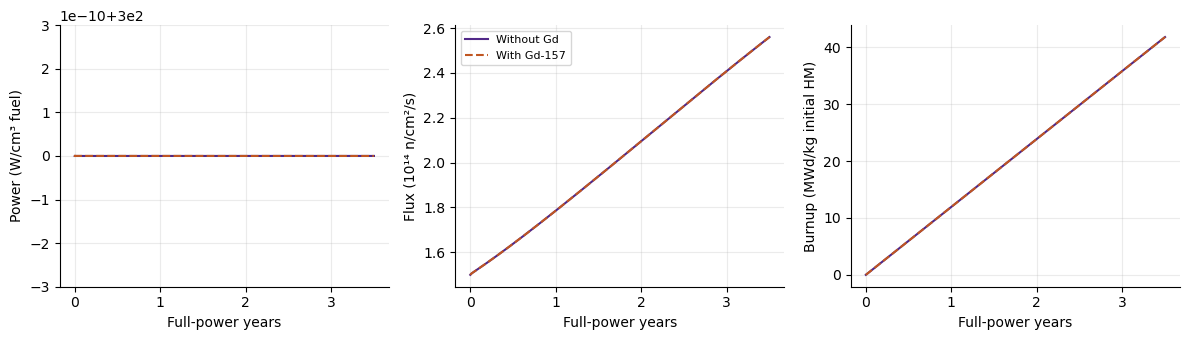

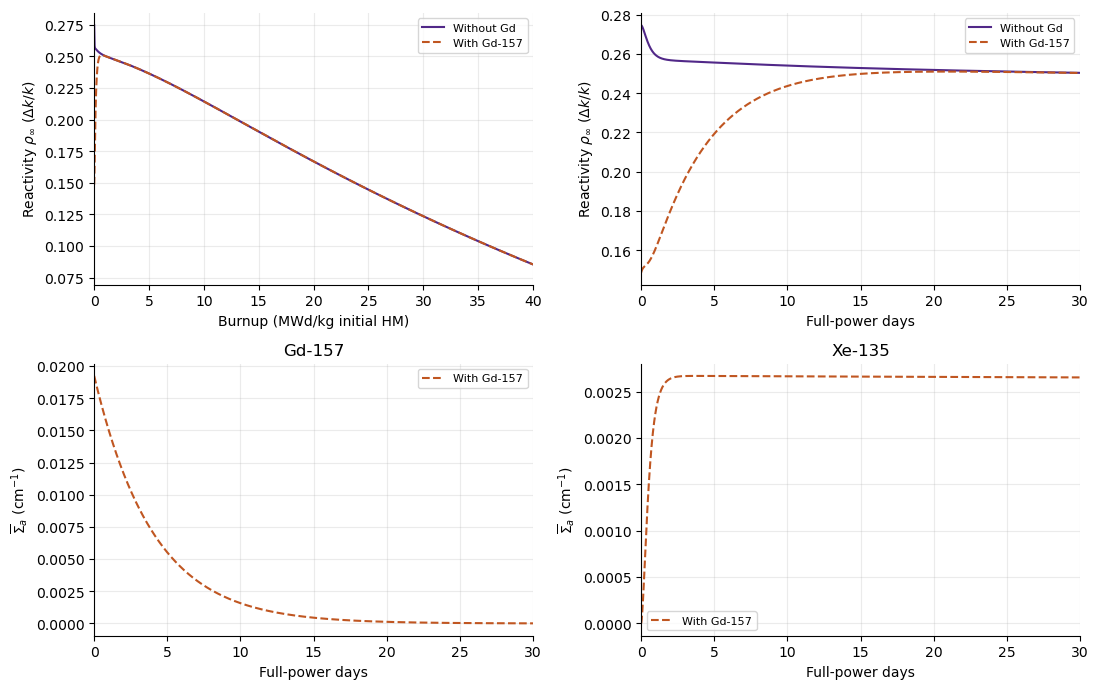

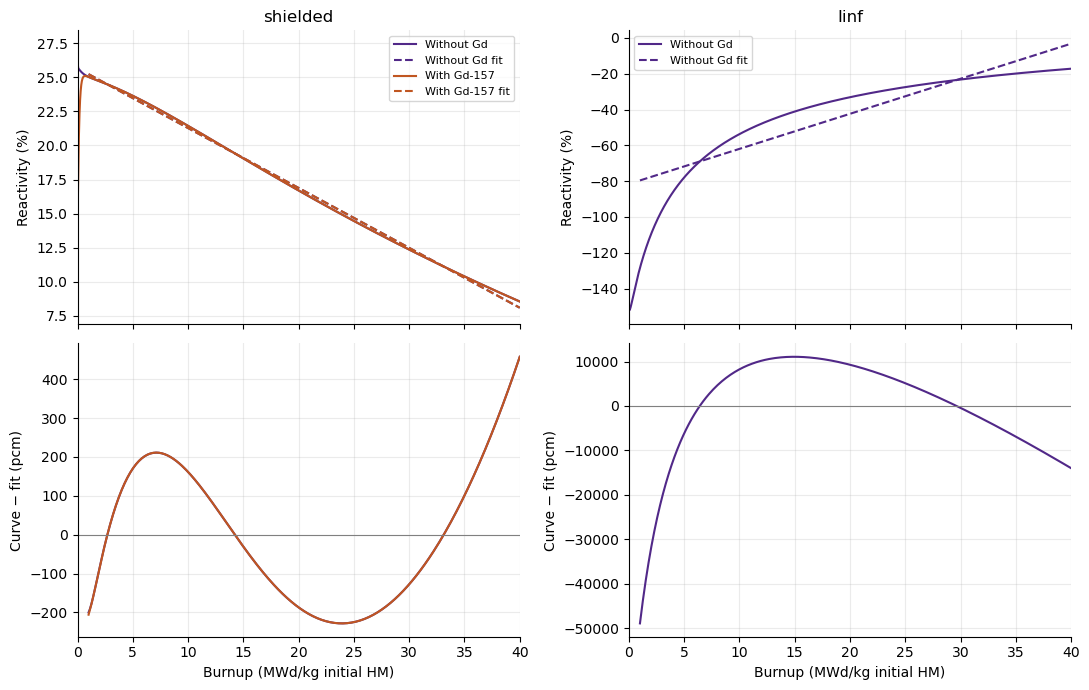

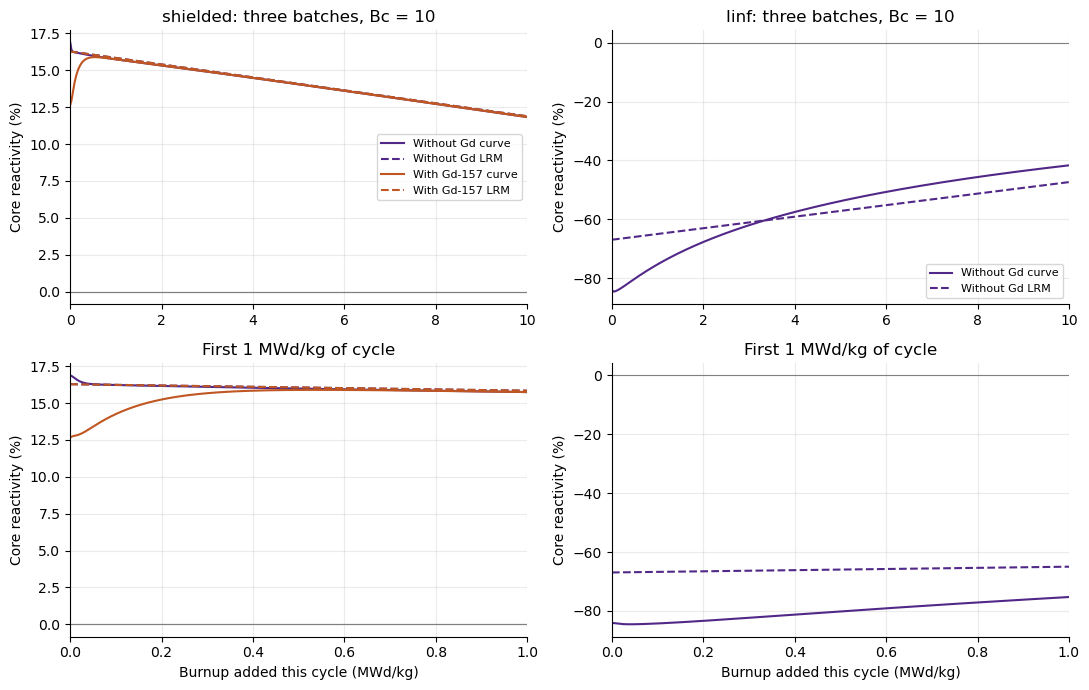

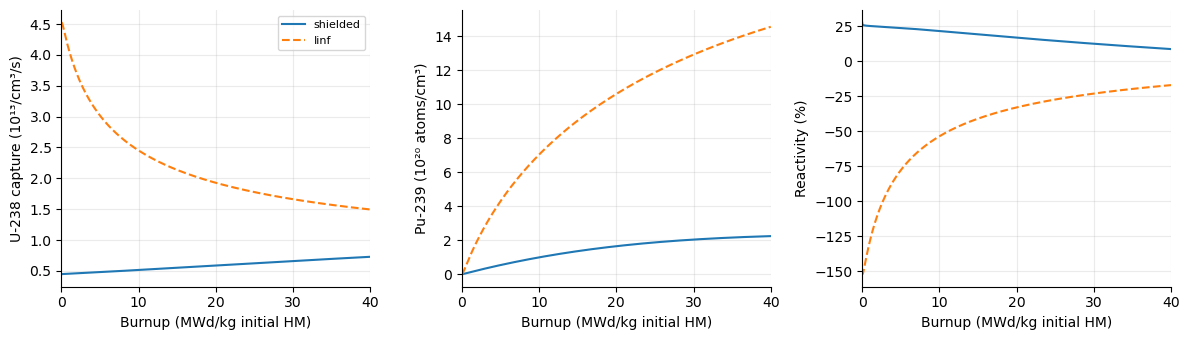

In [5]:
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"no_Gd": "#512888", "Gd": "#c05621"}
LABELS = {"no_Gd": "Without Gd", "Gd": "With Gd-157"}


def finish(fig, name):
    for ax in fig.axes:
        ax.grid(alpha=.25)
    fig.tight_layout()
    fig.savefig(FIG / f"hw24_{name}.png", dpi=170)
    plt.show()
    plt.close(fig)


fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for bp in LOADINGS:
    r = RESULTS["shielded", bp]
    for ax, values, ylabel in zip(axes,
            (r.power_density_w_cm3, r.total_flux/1e14, r.burnup_mwd_kg),
            ("Power (W/cm³ fuel)", "Flux (10¹⁴ n/cm²/s)", "Burnup (MWd/kg initial HM)")):
        ax.plot(r.time_s/YEAR, values, color=COLORS[bp],
                linestyle="-" if bp == "no_Gd" else "--", label=LABELS[bp])
        ax.set(xlabel="Full-power years", ylabel=ylabel)
axes[1].legend(fontsize=8)
finish(fig, "power_flux_burnup")

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for bp in LOADINGS:
    r = RESULTS["shielded", bp]
    rho = r.neutronics()["rho"]
    startup = r.time_s <= 30*DAY
    style = "-" if bp == "no_Gd" else "--"
    axes[0,0].plot(r.burnup_mwd_kg, rho, color=COLORS[bp], linestyle=style, label=LABELS[bp])
    axes[0,1].plot(r.time_s[startup]/DAY, rho[startup], color=COLORS[bp], linestyle=style, label=LABELS[bp])
    if bp == "Gd":
        for ax, name in zip(axes[1,:], ("Gd157", "Xe135")):
            ax.plot(r.time_s[startup]/DAY, poison_absorption(r, name)[startup], color=COLORS[bp],
                    linestyle=style, label=LABELS[bp])
axes[0,0].set(xlim=(0, 40), xlabel="Burnup (MWd/kg initial HM)", ylabel=r"Reactivity $\rho_\infty$ ($\Delta k/k$)")
axes[0,1].set(xlim=(0, 30), xlabel="Full-power days", ylabel=r"Reactivity $\rho_\infty$ ($\Delta k/k$)")
for ax, isotope in zip(axes[1,:], ("Gd-157", "Xe-135")):
    ax.set(xlim=(0, 30), xlabel="Full-power days", ylabel=r"$\overline{\Sigma}_a$ (cm$^{-1}$)", title=isotope)
for ax in axes.flat:
    ax.legend(fontsize=8)
finish(fig, "startup")

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for j, xs_key in enumerate(XS):
    for bp in LOADINGS:
        if (xs_key, bp) not in RESULTS:
            continue
        r = RESULTS[xs_key, bp]
        row = SUMMARY.loc[f"{xs_key}_{bp}"]
        curve = interpolate_checked(FIT_B, r.burnup_mwd_kg, r.neutronics()["rho"])
        line = row.rho0+row.signed_slope*FIT_B
        axes[0,j].plot(r.burnup_mwd_kg, 100*r.neutronics()["rho"], color=COLORS[bp], label=LABELS[bp])
        axes[0,j].plot(FIT_B, 100*line, "--", color=COLORS[bp], label=LABELS[bp]+" fit")
        axes[1,j].plot(FIT_B, 1e5*(curve-line), color=COLORS[bp])
    axes[0,j].set(title=xs_key, ylabel="Reactivity (%)", xlim=(0, 40))
    axes[0,j].legend(fontsize=8)
    axes[1,j].set(xlabel="Burnup (MWd/kg initial HM)", ylabel="Curve − fit (pcm)")
    axes[1,j].axhline(0, color="gray", lw=.8)
finish(fig, "fits")

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for j, xs_key in enumerate(XS):
    for bp in LOADINGS:
        if (xs_key, bp) not in RESULTS:
            continue
        r = RESULTS[xs_key, bp]
        row = SUMMARY.loc[f"{xs_key}_{bp}"]
        q, core = core_curve(r)
        line = row.rho0-RHO_L-row.A*(10+q)
        for ax in axes[:,j]:
            ax.plot(q, 100*core, color=COLORS[bp], label=LABELS[bp]+" curve")
            ax.plot(q, 100*line, "--", color=COLORS[bp], label=LABELS[bp]+" LRM")
            ax.axhline(0, color="gray", lw=.8)
    axes[0,j].set(title=f"{xs_key}: three batches, Bc = 10", xlim=(0,10), ylabel="Core reactivity (%)")
    axes[1,j].set(xlim=(0,1), xlabel="Burnup added this cycle (MWd/kg)", ylabel="Core reactivity (%)")
    axes[0,j].legend(fontsize=8)
    axes[1,j].set_title("First 1 MWd/kg of cycle")
finish(fig, "core10")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for xs_key, style in (("shielded", "-"), ("Iinf", "--")):
    r = RESULTS[xs_key, "no_Gd"]
    b = r.burnup_mwd_kg
    cap = r.total_flux*BARN*r.density("U238")*np.dot(r.xs3["U238"].capture_b, SPECTRUM)
    axes[0].plot(b, cap/1e13, style, label=xs_key)
    axes[1].plot(b, r.density("Pu239")/1e20, style)
    axes[2].plot(b, 100*r.neutronics()["rho"], style)
for ax, ylabel in zip(axes, ("U-238 capture (10¹³/cm³/s)", "Pu-239 (10²⁰ atoms/cm³)", "Reactivity (%)")):
    ax.set(xlim=(0,40), xlabel="Burnup (MWd/kg initial HM)", ylabel=ylabel)
axes[0].legend(fontsize=8)
finish(fig, "cross_section_effect")

## Retained evidence and LaTeX tables

In [6]:
# Remove derived histories for the case omitted from the revised assignment.
for obsolete in ("Iinf_Gd.csv.gz", "Iinf_Gd_core10.csv"):
    (DATA / obsolete).unlink(missing_ok=True)
SUMMARY.to_csv(DATA / "summary.csv", float_format="%.12g")
pd.DataFrame(ERRORS).to_csv(DATA / "formal_errors.csv", index=False, float_format="%.12g")
pd.DataFrame(CHECKS).to_csv(DATA / "verification.csv", index=False, float_format="%.12g")
pd.DataFrame(STARTER_COMPARISON).to_csv(DATA / "starter_sampling_comparison.csv", index=False, float_format="%.12g")
POISON_ROWS = []
POISON_HISTORIES = []
for bp in ("Gd",):
    r = RESULTS["shielded", bp]
    mask = r.time_s <= 30*DAY
    gd = poison_absorption(r, "Gd157")
    xe = poison_absorption(r, "Xe135")
    POISON_HISTORIES.append(pd.DataFrame(dict(
        case=bp, time_days=r.time_s[mask]/DAY,
        Sigma_a_Gd157_cm1=gd[mask], Sigma_a_Xe135_cm1=xe[mask],
    )))
    POISON_ROWS.append(dict(bp=bp, gd_0=float(gd[0]), xe_0=float(xe[0]),
        gd_30=float(interpolate_checked(30*DAY, r.time_s, gd)),
        xe_30=float(interpolate_checked(30*DAY, r.time_s, xe))))
pd.concat(POISON_HISTORIES, ignore_index=True).to_csv(
    DATA / "poison_absorption_0_30_days.csv", index=False, float_format="%.12g")
pd.DataFrame(POISON_ROWS).to_csv(DATA / "poison_absorption_endpoints.csv", index=False, float_format="%.12g")
print("\nSpectrum-averaged macroscopic absorption (cm^-1), shielded cases:")
print(pd.DataFrame(POISON_ROWS).to_string(index=False))
for key, result in RESULTS.items():
    label = "_".join(key)
    # Retain the full inventories compactly; pandas.read_csv reads .gz directly.
    csv_path = DATA / f"{label}.csv"
    result.to_csv(str(csv_path))
    (DATA / f"{label}.csv.gz").write_bytes(gzip.compress(csv_path.read_bytes(), mtime=0))
    csv_path.unlink()
    q, core = core_curve(result)
    pd.DataFrame(dict(b_MWd_kg=q, core_rho=core)).to_csv(DATA / f"{label}_core10.csv", index=False)

PROVENANCE = dict(
    python=platform.python_version(), numpy=np.__version__, scipy=scipy.__version__, pandas=pd.__version__,
    module_sha256=hashlib.sha256((ROOT / "code/ne630_depletion.py").read_bytes()).hexdigest(),
    assignment_sha256=hashlib.sha256((ROOT / "homework/markdown/HW24.md").read_bytes()).hexdigest(),
    integrals_b={k: float(xs["U238"].absorption_b[1]*LETHARGY_WIDTH) for k, xs in XS.items()},
    solver_info={"_".join(k): r.solver_info for k, r in RESULTS.items()},
    checks_passed=len(CHECKS),
    refined_summary=[summarize(r, *k) for k, r in REFINED.items()],
)
(DATA / "provenance.json").write_text(json.dumps(PROVENANCE, indent=2)+"\n")


def tex_table(name, headers, rows):
    text = "\\begin{center}\\small\n\\begin{tabular}{"+"l"+"r"*(len(headers)-1)+"}\n\\toprule\n"
    text += " & ".join(headers)+r" \\"+"\n\\midrule\n"
    text += "\n".join(" & ".join(row)+r" \\" for row in rows)
    text += "\n\\bottomrule\n\\end{tabular}\n\\end{center}\n"
    (DATA / (name+".tex")).write_text(text)


short = {"shielded_no_Gd": "Shielded, no Gd", "shielded_Gd": "Shielded, Gd",
         "Iinf_no_Gd": r"$I_\infty$, no Gd"}
tex_table("fits", ["Case", r"$\rho_0$", r"$-a$", "RMS (pcm)", "Max (pcm)"],
          [[short[k], f"{r.rho0:.6f}", f"{r.signed_slope:.8f}", f"{r.rms_pcm:.1f}", f"{r.max_abs_pcm:.1f}"]
           for k, r in SUMMARY.iterrows()])
tex_table("cycles", ["Case", r"$B_c$", r"$B_d$", "Days", "LRM assumptions"],
          [[short[k], f"{r.formal_Bc:.3f}", f"{r.formal_Bd:.3f}", f"{r.formal_cycle_days:.2f}",
            "satisfied" if r.decreasing_LRM_valid else "INVALID"] for k,r in SUMMARY.iterrows()])
tex_table("startup", ["Shielded case", r"$\rho(0)$", "Min", "Max", "Swing (pcm)"],
          [[short[k], f"{r.rho_initial:.6f}", f"{r.rho_min_0_40:.6f}", f"{r.rho_max_0_40:.6f}", f"{r.swing_pcm:.0f}"]
           for k,r in SUMMARY.iterrows() if r["xs"] == "shielded"])
# Output regression: physics checks alone cannot detect an empty rendered table.
# Explicit Series indexing avoids the pandas Series.xs method-name collision.
startup_tex = (DATA / "startup.tex").read_text()
expected_startup_rows = (
    "Shielded, no Gd & 0.274681 & 0.085500 & 0.274681 & 18918",
    "Shielded, Gd & 0.148613 & 0.085500 & 0.251014 & 16551",
)
for expected_row in expected_startup_rows:
    assert startup_tex.count(expected_row) == 1, f"Missing/duplicate startup row: {expected_row}"
assert sum(line.startswith("Shielded, ") for line in startup_tex.splitlines()) == 2
print("PASS: startup.tex renders both expected shielded data rows and exact reference values.")

tex_table("core10", ["Case", "Curve BOC", "Curve EOC", "LRM BOC", "LRM EOC"],
          [[short[k], *[f"{r[n]:.6f}" for n in ("core10_BOC", "core10_EOC", "core10_LRM_BOC", "core10_LRM_EOC")]]
           for k,r in SUMMARY.iterrows()])
tex_table("errors", ["BP case", r"$\Delta B_c$", r"$\Delta t$ (days)", r"Formal $L$ (\$M)"],
          [[LABELS[r["bp"]], f"{r['formal_delta_Bc']:.4f}", f"{r['formal_delta_days']:.3f}",
            f"{r['formal_million_dollars']:.3f}"] for r in ERRORS])


def scientific_tex(value):
    if value == 0:
        return "0"
    mantissa, exponent = f"{value:.5e}".split("e")
    return rf"${mantissa}\times10^{{{int(exponent)}}}$"


tex_table("poisons", ["Case", "Gd-157, day 0", "Gd-157, day 30", "Xe-135, day 0", "Xe-135, day 30"],
          [[LABELS[r["bp"]], *[scientific_tex(r[k]) for k in ("gd_0", "gd_30", "xe_0", "xe_30")]]
           for r in POISON_ROWS])
print("\nWrote numerical evidence to", DATA)


Spectrum-averaged macroscopic absorption (cm^-1), shielded cases:
bp     gd_0  xe_0   gd_30    xe_30
Gd 0.019236   0.0 0.00001 0.002656



Wrote numerical evidence to /home/robertsj/Classes/ne630/homework/solutions/data/hw24
